# Phase 2 (Gemini): runtime validator (policy graph as code)

**Goal:** the control arm for H1, on Gemini. Same agent, model and prose prompt as 05G. The only change: a validator sits between the agent and the database.

**How it works:** before a write tool runs, `policy_checker.py` checks the `data` rules from `airline_policy_graph.json` on the live database. If a rule fails, the call is **blocked** and the agent gets an error that names the rule (e.g. C3). `dialogue` rules can't be checked here and never block.

**Run first:** 05G (it writes `settings_gemini.py` and `gemini_run.py`) and 04 (the graph `airline_policy_graph.json`). This notebook writes its own `policy_checker.py`, `violations.py` and `validator_gemini.py`.

**Runtime:** CPU only. No GPU.

**Model and cost:** whatever `settings_gemini.py` says (written by 05G), now `gemini-3.1-flash-lite` on the paid Gemini API. Same model as 05G, so the two arms can be compared. Cost: about $6.20 for 400 dialogues.

**Run:** 50 tasks × 8 trials. Results in `results_gemini_validator/trial_1..8/`, blocks in `trial_k/blocks.jsonl`.

**Two findings from building the validator (they don't depend on the model):**
1. In 8 tasks the answer key itself breaks `wiki.md` (10, 16, 19, 26, 27, 34, 45, 46), so I report all 50 tasks and the 42 clean tasks.
2. τ-bench's `update_reservation_flights` doesn't save the new cabin; the checker handles it.

The validator is off while τ-bench replays the answer key for scoring, so the answer key is the same as in 05G.

**Result in one line:** pass^1 0.573 vs 0.525 (baseline); on the 42 clean tasks Δpass^1 = +0.104, significant; Δpass^8 = +0.048, not significant. Details in the Summary at the end.

In [1]:
# mount Google Drive so results are saved
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
# go into the repo and install tau-bench (CPU runtime)
%cd /content/drive/MyDrive/cmsc691-10-project2
!pip install -q -e .
!pip install -q mcp
print("installed")

/content/drive/MyDrive/cmsc691-10-project2
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for tau_bench (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-cloud-dataproc 5.32.0 requires protobuf<8.0.0,>=6.33.5, but you have protobuf 5.29.6 which is incompatible.
google-cloud-bigquery-storage 2.43.0 requires protobuf<8.0.0,>=6.33.5, but you have protobuf 5.29.6 which is incompatible.
google-cloud-resource-manager 1.19.0 requires protobuf<8.0.0,>=6.33.5, but you have protobuf 5.29.6 which is incompatible.
google-cloud-bigquery-connection 1.23.0 requires protobuf<8.0.0,>=6.33.5, but you have protobuf 5.29.6 which is incompatible.
tensorflow 2.21.0 requires 

In [4]:
# load settings, connect to Gemini (API key or Colab), and check tool calling once
import os, sys, re, importlib, logging, warnings
import pandas as pd
from IPython.display import display
sys.path.insert(0, "/content/drive/MyDrive/cmsc691-10-project2")
os.chdir("/content/drive/MyDrive/cmsc691-10-project2")
for f in ["settings_gemini.py", "gemini_run.py", "airline_policy_graph.json", "passk.py"]:
    assert os.path.exists(f), f"{f} missing: run 05G (Gemini files) and 04 (the graph) first"
importlib.invalidate_caches()
import settings_gemini; importlib.reload(settings_gemini)
from settings_gemini import *
warnings.filterwarnings("ignore")
logging.getLogger("LiteLLM").setLevel(logging.ERROR)   # hide litellm's long warnings

def short_error(e):
    # keep only the API's own message, one line
    m = re.search(r'"message":\s*"([^"]+)"', str(e))
    return (m.group(1) if m else str(e).splitlines()[0])[:200]

def set_token():
    if BACKEND == "colab":
        # the Colab token can expire, so I get a fresh one before each run
        from google.colab import ai
        os.environ["COLAB_PROXY_BASE"] = f"{ai._get_model_proxy_host()}/models/openapi"
        os.environ["COLAB_PROXY_KEY"] = ai._get_model_proxy_token()
    else:
        # my key from Colab Secrets (name GEMINI_API_KEY); never printed
        from google.colab import userdata
        os.environ["GEMINI_API_KEY"] = userdata.get("GEMINI_API_KEY")
set_token()

display(pd.DataFrame({"setting": [k for k in vars(settings_gemini) if k.isupper()],
                       "value": [vars(settings_gemini)[k] for k in vars(settings_gemini) if k.isupper()]})
        .set_index("setting").T)

import litellm
litellm.suppress_debug_info = True
tools = [{"type": "function", "function": {
    "name": "get_reservation", "description": "Look up a reservation",
    "parameters": {"type": "object", "properties": {"reservation_id": {"type": "string"}},
                   "required": ["reservation_id"]}}}]
if BACKEND == "colab":
    kw = dict(model=PROXY_PREFIX + MODEL, custom_llm_provider="openai",
              api_base=os.environ["COLAB_PROXY_BASE"], api_key=os.environ["COLAB_PROXY_KEY"])
else:
    kw = dict(model=MODEL, custom_llm_provider="gemini", api_key=os.environ["GEMINI_API_KEY"])
try:
    r = litellm.completion(**kw, temperature=0.0, tools=tools,
                           messages=[{"role": "user", "content": "Look up reservation ABC123."}])
    ok = bool(r.choices[0].message.tool_calls)
    print(f"{'✅ tool call works' if ok else '❌ no tool call'} | model {MODEL}")
except Exception as e:
    print(f"❌ {type(e).__name__}: {short_error(e)}")
    print("Fix MODEL in settings_gemini.py (05G, cell 3), run that cell in 05G, then this cell again.")

setting,BACKEND,MODEL,PRICE_IN,PRICE_OUT,PROXY_PREFIX,TEMPERATURE,USER_TEMPERATURE,CONCURRENCY,NUM_RETRIES,CALL_TIMEOUT,ENV,N_TASKS,N_TRIALS
value,apikey,gemini-3.1-flash-lite,0.25,1.5,google/,0.0,1.0,4,6,600,airline,50,8


✅ tool call works | model gemini-3.1-flash-lite


In [6]:
%%writefile /content/drive/MyDrive/cmsc691-10-project2/policy_checker.py
# Policy checker for tau-bench airline, built from airline_policy_graph.json.
#
# The graph decides WHICH rules apply to an action and how they combine
# (OR / AND gates). This file only says how to test each "data" rule
# against the database. "dialogue" rules can't be seen here, so they count
# as unknown and never block (a validator can't read the chat).
#
# Evaluation: each rule gives True / False / None (unknown).
#   AND -> False if any False, else None if any None, else True
#   OR  -> True if any True,  else None if any None, else False
# A top-level condition that comes out False is a violation.
import json
import os
from datetime import datetime, timedelta

NOW = datetime(2024, 5, 15, 15, 0, 0)          # wiki.md: "The current time is 2024-05-15 15:00:00 EST"
WRITE_TOOLS = {"book_reservation", "update_reservation_flights", "update_reservation_baggages",
               "update_reservation_passengers", "cancel_reservation", "send_certificate"}
FLOWN = {"flying", "landed"}

_HERE = os.path.dirname(os.path.abspath(__file__))
GRAPH_PATH = os.environ.get("POLICY_GRAPH", os.path.join(_HERE, "airline_policy_graph.json"))


# ---------------------------------------------------------------- helpers
def _status(data, flight_number, date):
    f = data["flights"].get(flight_number)
    if not f or date not in f["dates"]:
        return None
    return f["dates"][date]["status"]


def _segments(flights):
    return {(f["flight_number"], f["date"]) for f in flights}


def _user_reservations(ctx):
    user = ctx["user"]
    if not user:
        return []
    return [ctx["data"]["reservations"][r] for r in user.get("reservations", [])
            if r in ctx["data"]["reservations"]]


def _cabin(ctx, res):
    """Real cabin of a reservation. tau-bench's update_reservation_flights never saves
    the new cabin, so I take it from earlier successful calls in this dialogue."""
    cabin = res["cabin"]
    for h in ctx["history"]:
        if h["name"] == "update_reservation_flights" and h["kwargs"].get("reservation_id") == res["reservation_id"]:
            cabin = h["kwargs"].get("cabin", cabin)
    return cabin


def _endpoints(data, flights):
    """(first origin, last destination, all destinations) of a list of flight segments."""
    legs = [data["flights"].get(f["flight_number"]) for f in flights]
    if not legs or any(l is None for l in legs):
        return None
    return legs[0]["origin"], legs[-1]["destination"], {l["destination"] for l in legs}


# ---------------------------------------------------------------- data rules
# key = rule id in the graph: "<action>/c<k>" plus ".<j>" inside OR/AND gates
# (same ids as load_neo4j.py). Each returns True, False or None.
def r_book_status(ctx):                       # D3
    return all(_status(ctx["data"], f["flight_number"], f["date"]) == "available"
               for f in ctx["kw"].get("flights", []))


def r_book_max5(ctx):                         # B2
    return len(ctx["kw"].get("passengers", [])) <= 5


def r_book_same_flights_cabin(ctx):           # B2 (one cabin and one flight list per call)
    return True


def r_book_payment_limits(ctx):               # B3
    pm = ctx["user"]["payment_methods"] if ctx["user"] else {}
    src = [pm.get(p["payment_id"], {}).get("source") for p in ctx["kw"].get("payment_methods", [])]
    return src.count("certificate") <= 1 and src.count("credit_card") <= 1 and src.count("gift_card") <= 3


def r_book_payment_in_profile(ctx):           # B3
    pm = ctx["user"]["payment_methods"] if ctx["user"] else {}
    return all(p["payment_id"] in pm for p in ctx["kw"].get("payment_methods", []))


def r_flights_not_basic(ctx):                 # M2
    return _cabin(ctx, ctx["res"]) != "basic_economy"


def r_flights_same_od_type(ctx):              # M2
    res, data = ctx["res"], ctx["data"]
    ends = _endpoints(data, ctx["kw"].get("flights", []))
    if ends is None:
        return None
    first_o, last_d, dests = ends
    if res["flight_type"] == "one_way":
        return first_o == res["origin"] and last_d == res["destination"]
    return first_o == res["origin"] and last_d == res["origin"] and res["destination"] in dests


def r_flights_payment_gc_cc(ctx):             # M6
    pm = ctx["user"]["payment_methods"] if ctx["user"] else {}
    return pm.get(ctx["kw"].get("payment_id"), {}).get("source") in ("gift_card", "credit_card")


def r_cabin_flights_same(ctx):                # M3 (checked only when the flights are unchanged)
    return _segments(ctx["kw"].get("flights", [])) == _segments(ctx["res"]["flights"])


def r_cabin_same_all(ctx):                    # M3 (one cabin per call)
    return True


def r_bags_not_lower(ctx):                    # M4
    return ctx["kw"].get("total_baggages", 0) >= ctx["res"]["total_baggages"]


def r_bags_no_insurance(ctx):                 # M4 (this tool can't add insurance)
    return True


def r_pax_same_count(ctx):                    # M5
    return len(ctx["kw"].get("passengers", [])) == len(ctx["res"]["passengers"])


def r_cancel_not_flown(ctx):                  # C3
    return all(_status(ctx["data"], f["flight_number"], f["date"]) not in FLOWN
               for f in ctx["res"]["flights"])


def r_cancel_24h(ctx):                        # C2
    created = datetime.fromisoformat(ctx["res"]["created_at"])
    return NOW - created <= timedelta(hours=24)


def r_cancel_airline_cancelled(ctx):          # C2
    return any(_status(ctx["data"], f["flight_number"], f["date"]) == "cancelled"
               for f in ctx["res"]["flights"])


def r_cancel_business(ctx):                   # C2
    return _cabin(ctx, ctx["res"]) == "business"


def r_cancel_insurance(ctx):                  # C2
    return ctx["res"].get("insurance") == "yes"


# send_certificate has no reservation id, so reservation rules look at the
# user's reservations: True if any one of them fits (the agent may mean it).
def r_cert_member(ctx):                       # R1
    return bool(ctx["user"]) and ctx["user"]["membership"] in ("silver", "gold")


def r_cert_insurance(ctx):                    # R1
    return any(r.get("insurance") == "yes" for r in _user_reservations(ctx))


def r_cert_business(ctx):                     # R1
    return any(_cabin(ctx, r) == "business" for r in _user_reservations(ctx))


def _any_flight_status(ctx, status):
    return any(_status(ctx["data"], f["flight_number"], f["date"]) == status
               for r in _user_reservations(ctx) for f in r["flights"])


def r_cert_fact_cancelled(ctx):               # R1
    return _any_flight_status(ctx, "cancelled")


def r_cert_fact_delayed(ctx):                 # R2
    return _any_flight_status(ctx, "delayed")


def r_cert_change_first(ctx):                 # R2: a change or cancel happened earlier in this dialogue
    return any(a in ("update_reservation_flights", "update_reservation_baggages",
                     "update_reservation_passengers", "cancel_reservation") for a in
               (h["name"] for h in ctx["history"]))


DATA_RULES = {
    "book_reservation/c0": r_book_status,
    "book_reservation/c1": r_book_max5,
    "book_reservation/c2": r_book_same_flights_cabin,
    "book_reservation/c3": r_book_payment_limits,
    "book_reservation/c4": r_book_payment_in_profile,
    "update_reservation_flights/c0": r_flights_not_basic,
    "update_reservation_flights/c1": r_flights_same_od_type,
    "update_reservation_flights/c2": r_flights_payment_gc_cc,
    "upgrade_cabin/c0": r_cabin_flights_same,
    "upgrade_cabin/c1": r_cabin_same_all,
    "update_reservation_baggages/c0": r_bags_not_lower,
    "update_reservation_baggages/c1": r_bags_no_insurance,
    "update_reservation_passengers/c0": r_pax_same_count,
    "cancel_reservation/c0": r_cancel_not_flown,
    "cancel_reservation/c1.0": r_cancel_24h,
    "cancel_reservation/c1.1": r_cancel_airline_cancelled,
    "cancel_reservation/c1.2": r_cancel_business,
    "cancel_reservation/c1.3.0": r_cancel_insurance,
    "send_certificate/c1.0": r_cert_member,
    "send_certificate/c1.1": r_cert_insurance,
    "send_certificate/c1.2": r_cert_business,
    "send_certificate/c2.0.1": r_cert_fact_cancelled,
    "send_certificate/c2.1.1": r_cert_fact_delayed,
    "send_certificate/c2.1.2": r_cert_change_first,
}


# ---------------------------------------------------------------- graph walk
def load_graph(path=GRAPH_PATH):
    g = json.load(open(path))
    actions = {a["action"]: a for a in g["actions"]}
    # every data rule in the graph must have code, and no code without a rule
    ids = set()

    def walk(c, cid):
        if "any_of" in c or "all_of" in c:
            for j, s in enumerate(c.get("any_of", []) + c.get("all_of", [])):
                walk(s, f"{cid}.{j}")
        elif c["check"] == "data":
            ids.add(cid)
    for a in g["actions"]:
        for k, c in enumerate(a["conditions"]):
            walk(c, f"{a['action']}/c{k}")
    missing, extra = ids - set(DATA_RULES), set(DATA_RULES) - ids
    assert not missing and not extra, f"graph and code differ: missing={missing} extra={extra}"
    return actions


def _eval(c, cid, ctx, failed):
    if "any_of" in c or "all_of" in c:
        subs = [_eval(s, f"{cid}.{j}", ctx, failed)
                for j, s in enumerate(c.get("any_of", []) + c.get("all_of", []))]
        if "all_of" in c:
            return False if False in subs else (None if None in subs else True)
        return True if True in subs else (None if None in subs else False)
    if c["check"] == "dialogue":
        return None
    ok = DATA_RULES[cid](ctx)
    if ok is False:
        failed.append((cid, c["source"], c["condition"]))
    return ok


def graph_actions_for(tool, kw, data, history=()):
    """Which graph actions a tool call stands for (one tool can be two graph actions)."""
    if tool != "update_reservation_flights":
        return [tool]
    res = data["reservations"].get(kw.get("reservation_id"))
    if res is None:
        return []
    out = []
    if _segments(kw.get("flights", [])) != _segments(res["flights"]):
        out.append("update_reservation_flights")
    elif kw.get("cabin") != _cabin({"history": history}, res):
        out.append("upgrade_cabin")
    return out


def check(tool, kw, data, history, graph):
    """Violations of data rules for one write tool call, before it runs.
    history = earlier calls in this dialogue that ran without error: [{"name", "kwargs"}]."""
    if tool not in WRITE_TOOLS:
        return []
    res = data["reservations"].get(kw.get("reservation_id")) if "reservation_id" in kw else None
    uid = kw.get("user_id") or (res or {}).get("user_id")
    user = data["users"].get(uid)
    if "reservation_id" in kw and res is None:
        return []                      # the tool itself will say "reservation not found"
    if tool in ("book_reservation", "send_certificate") and user is None:
        return []                      # the tool itself will say "user not found"
    ctx = {"data": data, "kw": kw, "res": res, "user": user, "history": history}
    out = []
    for act in graph_actions_for(tool, kw, data, history):
        for k, cond in enumerate(graph[act]["conditions"]):
            failed = []
            if _eval(cond, f"{act}/c{k}", ctx, failed) is False:
                out.append({"action": act, "rule": f"{act}/c{k}",
                            "sources": sorted({s for _, s, _ in failed}),
                            "failed": [t for _, _, t in failed],
                            "if_fails": cond.get("if_fails", "deny")})
    return out


def message(violations):
    """What the agent sees when the validator blocks a call."""
    lines = ["Error: blocked by the policy validator. The call was NOT executed."]
    for v in violations:
        lines.append(f"- {v['action']} breaks {', '.join(v['sources'])}: " + "; ".join(v["failed"]))
    if any(v["if_fails"] == "transfer_to_human_agents" for v in violations):
        lines.append("Policy: transfer the user to a human agent.")
    else:
        lines.append("Policy: deny this request and tell the user why.")
    return "\n".join(lines)

Overwriting /content/drive/MyDrive/cmsc691-10-project2/policy_checker.py


In [7]:
%%writefile /content/drive/MyDrive/cmsc691-10-project2/violations.py
# Count policy violations in saved tau-bench runs (secondary metric).
# I replay every tool call of a dialogue on a fresh copy of the database,
# and check each write call with policy_checker BEFORE it runs.
# Works for any arm: a call the validator blocked is counted as "blocked",
# a bad call that really ran is counted as "executed".
import json
from collections import Counter

import policy_checker as pc
from tau_bench.envs.airline.data import load_data
from tau_bench.envs.airline.tools import ALL_TOOLS

TOOLS = {t.get_info()["function"]["name"]: t for t in ALL_TOOLS}
BLOCK_TAG = "Error: blocked by the policy validator"

# tasks where tau-bench's answer key itself breaks the written policy
# (found by running the checker on the ground-truth actions, see 06)
LABEL_CONFLICT = [10, 16, 19, 26, 27, 34, 45, 46]


def ran_calls(traj):
    """(name, kwargs, observation) for every tool call that got a tool reply, in order."""
    obs = {m["tool_call_id"]: m["content"] for m in traj if m.get("role") == "tool"}
    out = []
    for m in traj:
        for c in (m.get("tool_calls") or []) if m.get("role") == "assistant" else []:
            if c["id"] in obs:
                try:
                    kw = json.loads(c["function"]["arguments"] or "{}")
                except json.JSONDecodeError:
                    kw = None
                out.append((c["function"]["name"], kw, obs[c["id"]]))
    return out


def replay(traj, graph):
    """Violations in one dialogue: list of dicts, plus a count of replay mismatches."""
    data, hist, found, mismatch = load_data(), [], [], 0
    for name, kw, obs in ran_calls(traj):
        if name not in TOOLS or not isinstance(kw, dict):
            continue
        blocked = str(obs).startswith(BLOCK_TAG)
        if name in pc.WRITE_TOOLS:
            for v in pc.check(name, kw, data, hist, graph):
                found.append({**v, "tool": name, "status": "blocked" if blocked else "executed"})
        if blocked:
            continue                                  # the validator did not run it, so I don't either
        try:
            out = TOOLS[name].invoke(data=data, **kw)
        except Exception as e:
            out = f"Error: {e}"
        if str(out) != str(obs):
            mismatch += 1                             # replay drifted from the real run
        if name in pc.WRITE_TOOLS and not str(out).startswith("Error"):
            hist.append({"name": name, "kwargs": kw})
    return found, mismatch


def count(tab, graph):
    """tab = passk.table(...) -> per-dialogue rows and totals."""
    rows, by_source, mism = [], Counter(), 0
    for trial, tasks in sorted(tab.items()):
        for t, r in sorted(tasks.items()):
            v, m = replay(r.get("traj") or [], graph)
            mism += m
            for x in v:
                for s in x["sources"]:
                    by_source[(s, x["status"])] += 1
            rows.append({"trial": trial, "task": t, "passed": r["reward"] >= 1 - 1e-6,
                         "executed": sum(x["status"] == "executed" for x in v),
                         "blocked": sum(x["status"] == "blocked" for x in v)})
    return rows, by_source, mism

Overwriting /content/drive/MyDrive/cmsc691-10-project2/violations.py


In [8]:
%%writefile /content/drive/MyDrive/cmsc691-10-project2/validator_gemini.py
# Arm 06 (Gemini): baseline agent + a runtime validator in front of the database.
# The agent, prompt and settings are the same as 05G (gemini_run.py runs them).
# Only change: before a write tool runs, policy_checker checks the data rules
# from the policy graph. If one fails, the call is blocked and the agent gets
# an error message instead. Every block is logged to a .jsonl file.
import json
import os
import runpy
import sys
import threading

import policy_checker as pc
from tau_bench.envs.base import Env
from tau_bench.types import EnvInfo, EnvResponse

GRAPH = pc.load_graph()                      # stops here if graph and code differ
LOG = os.environ.get("VALIDATOR_LOG", "validator_blocks.jsonl")
_lock = threading.Lock()

_real_reset, _real_step, _real_reward = Env.reset, Env.step, Env.calculate_reward


def reset(self, task_index=None):
    self._pc_hist = []                       # write calls that ran in this dialogue
    self._pc_off = False
    return _real_reset(self, task_index)


def calculate_reward(self):
    # tau-bench scores by replaying the answer key through step().
    # The validator must not touch that replay, or it changes the answer key.
    self._pc_off = True
    try:
        return _real_reward(self)
    finally:
        self._pc_off = False


def step(self, action):
    name, kw = action.name, action.kwargs
    if name in pc.WRITE_TOOLS and not self._pc_off:
        try:
            v = pc.check(name, kw, self.data, self._pc_hist, GRAPH)
        except Exception as e:               # a checker bug must never crash a run
            v = []
            print(f"[validator] checker error on {name}: {e}", file=sys.stderr)
        if v:
            self.actions.append(action)
            with _lock, open(LOG, "a") as f:
                f.write(json.dumps({"task_id": self.task_index, "tool": name, "kwargs": kw,
                                    "violations": v}) + "\n")
            return EnvResponse(observation=pc.message(v), reward=0, done=False,
                               info=EnvInfo(task=self.task, source=name))
    res = _real_step(self, action)
    if name in pc.WRITE_TOOLS and not self._pc_off and not str(res.observation).startswith("Error"):
        self._pc_hist.append({"name": name, "kwargs": kw})
    return res


Env.reset, Env.step, Env.calculate_reward = reset, step, calculate_reward

# same agent as the Gemini baseline: gemini_run.py patches litellm
# (and the user simulator) and calls run.main()
here = os.path.dirname(os.path.abspath(__file__))
runpy.run_path(os.path.join(here, "gemini_run.py"), run_name="__main__")

Overwriting /content/drive/MyDrive/cmsc691-10-project2/validator_gemini.py


In [9]:
# test the checker on tau-bench's answer key: correct actions should pass
# expected: 56 write actions, 8 blocked in tasks [10, 16, 19, 26, 27, 34, 45, 46]
import policy_checker as pc; importlib.reload(pc)
import violations as V; importlib.reload(V)
from tau_bench.envs.airline.tasks_test import TASKS
from tau_bench.envs.airline.data import load_data

graph = pc.load_graph()
n_write, conflict = 0, []
for i, t in enumerate(TASKS):
    data, hist = load_data(), []
    for a in t.actions:
        if a.name in pc.WRITE_TOOLS:
            n_write += 1
            if pc.check(a.name, a.kwargs, data, hist, graph):
                conflict.append(i)
        out = V.TOOLS[a.name].invoke(data=data, **a.kwargs)
        if a.name in pc.WRITE_TOOLS and not str(out).startswith("Error"):
            hist.append({"name": a.name, "kwargs": a.kwargs})
conflict = sorted(set(conflict))
print(f"write actions {n_write}, answer key breaks policy in {len(conflict)} tasks: {conflict}")
assert conflict == V.LABEL_CONFLICT
CLEAN = [t for t in range(N_TASKS) if t not in conflict]
print(f"clean tasks: {len(CLEAN)}")

write actions 56, answer key breaks policy in 8 tasks: [10, 16, 19, 26, 27, 34, 45, 46]
clean tasks: 42


In [10]:
# run the Gemini validator arm: 8 trials, one folder each, skip what is done
import os, sys, time, json, importlib
import passk; importlib.reload(passk)

%cd /content/drive/MyDrive/cmsc691-10-project2
OUT = "results_gemini_validator"
LOGS = "/content/drive/MyDrive/cmsc691-10-project2/logs_gemini"
os.makedirs(LOGS, exist_ok=True)
json.dump({**{k: v for k, v in vars(settings_gemini).items() if k.isupper()},
           "policy": "prose wiki.md + runtime validator (data rules of airline_policy_graph.json)",
           "backend": "Colab built-in Gemini" if BACKEND == "colab" else "paid Gemini API (AI Studio key)"},
          open(f"{OUT}_config.json", "w"), indent=2)

start_all = time.time()
for trial in range(1, N_TRIALS + 1):
    folder = f"{OUT}/trial_{trial}"
    os.makedirs(folder, exist_ok=True)
    todo = sorted(set(range(N_TASKS)) - passk.done_tasks(folder))
    if not todo:
        print(f"trial {trial}: done, skip")
        continue
    print(f"trial {trial}: running {len(todo)} tasks ...", end=" ", flush=True)
    t0 = time.time()
    ids = " ".join(map(str, todo))
    set_token()
    os.environ["CALL_LOG"] = f"{folder}/calls.jsonl"
    os.environ["VALIDATOR_LOG"] = f"{folder}/blocks.jsonl"
    log = f"{LOGS}/validator_trial_{trial}.log"
    !echo "===== run at $(date) =====" >> {log}
    !python validator_gemini.py --env {ENV} --agent-strategy tool-calling \
      --model {MODEL} --model-provider openai \
      --user-model {MODEL} --user-model-provider openai \
      --user-strategy llm --num-trials 1 --temperature {TEMPERATURE} \
      --task-ids {ids} --max-concurrency {CONCURRENCY} \
      --log-dir {folder} >> {log} 2>&1
    left = N_TASKS - len(passk.done_tasks(folder))
    print(f"{(time.time() - t0) / 60:.1f} min, {left} not done")
print(f"\nall trials: {(time.time() - start_all) / 60:.1f} min this session")
!grep -h "checker error" {LOGS}/validator_trial_*.log | head

/content/drive/MyDrive/cmsc691-10-project2
trial 1: done, skip
trial 2: done, skip
trial 3: done, skip
trial 4: done, skip
trial 5: done, skip
trial 6: done, skip
trial 7: done, skip
trial 8: done, skip

all trials: 0.0 min this session


In [11]:
# progress: tasks done and API errors per trial, as a table
import pandas as pd, importlib, passk; importlib.reload(passk)
from collections import Counter
from IPython.display import display
tab = passk.table("/content/drive/MyDrive/cmsc691-10-project2/results_gemini_validator")
prog = []
for trial in range(1, N_TRIALS + 1):
    rows = tab.get(trial, {})
    prog.append({"trial": trial, "done": f"{len(rows)}/{N_TASKS}",
                 "passed": sum(r["reward"] >= 1 - 1e-6 for r in rows.values()),
                 "API errors": sum(passk.is_error(r) for r in rows.values())})
display(pd.DataFrame(prog).set_index("trial").T)
kinds = Counter(short_error(r["info"]["error"]) for t in tab.values() for r in t.values() if passk.is_error(r))
for msg, c in kinds.most_common(3):
    print(f"{c} x {msg}")

trial,1,2,3,4,5,6,7,8
done,50/50,50/50,50/50,50/50,50/50,50/50,50/50,50/50
passed,28,29,26,29,30,28,28,31
API errors,0,0,0,0,0,0,0,0


baseline: complete trials 8
validator: complete trials 8

 k              baseline             validator
 1  0.525 [0.41,0.64]  0.573 [0.45,0.69]
 2  0.443 [0.32,0.57]  0.501 [0.38,0.62]
 3  0.406 [0.28,0.53]  0.460 [0.34,0.58]
 4  0.386 [0.27,0.52]  0.432 [0.31,0.56]
 5  0.376 [0.25,0.50]  0.412 [0.28,0.54]
 6  0.370 [0.24,0.51]  0.398 [0.27,0.53]
 7  0.365 [0.24,0.50]  0.388 [0.25,0.53]
 8  0.360 [0.22,0.50]  0.380 [0.26,0.52]


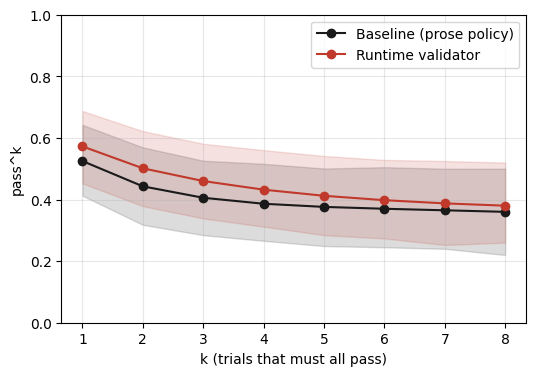

In [12]:
# pass^k curve with 95% CI: Gemini validator vs Gemini baseline
import os, csv
import matplotlib.pyplot as plt
import importlib, passk; importlib.reload(passk)

curves = {}
for name, d in [("baseline", "results_gemini_baseline"), ("validator", "results_gemini_validator")]:
    n, rows = passk.curve(f"/content/drive/MyDrive/cmsc691-10-project2/{d}", N_TASKS)
    curves[name] = rows
    print(f"{name}: complete trials {n}")
m = min(len(curves["baseline"]), len(curves["validator"]))
print(f"\n{'k':>2}  {'baseline':>20}  {'validator':>20}")
for k in range(1, m + 1):
    b, v = curves["baseline"][k - 1], curves["validator"][k - 1]
    print(f"{k:>2}  {b['pass^k']:.3f} [{b['ci_low']:.2f},{b['ci_high']:.2f}]  "
          f"{v['pass^k']:.3f} [{v['ci_low']:.2f},{v['ci_high']:.2f}]")
rows = curves["validator"]
if rows:
    with open("/content/drive/MyDrive/cmsc691-10-project2/results_gemini_validator_passk.csv", "w", newline="") as f:
        w = csv.DictWriter(f, fieldnames=rows[0].keys()); w.writeheader(); w.writerows(rows)
    plt.figure(figsize=(6, 4))
    for name, color, label in [("baseline", "#1A1A1A", "Baseline (prose policy)"),
                               ("validator", "#C0392B", "Runtime validator")]:
        r = curves[name]
        if not r: continue
        ks = [x["k"] for x in r]
        plt.fill_between(ks, [x["ci_low"] for x in r], [x["ci_high"] for x in r], alpha=0.15, color=color)
        plt.plot(ks, [x["pass^k"] for x in r], "o-", color=color, label=label)
    plt.xlabel("k (trials that must all pass)"); plt.ylabel("pass^k")
    plt.ylim(0, 1); plt.xticks(range(1, 9)); plt.grid(alpha=0.3); plt.legend()
    os.makedirs("/content/drive/MyDrive/cmsc691-10-project2/figures", exist_ok=True)
    plt.savefig("/content/drive/MyDrive/cmsc691-10-project2/figures/gemini_validator_passk.png", dpi=200, bbox_inches="tight")
    plt.show()

In [13]:
# paired comparison per task: same 50 tasks in both arms
# Δ = validator - baseline, 95% CI by resampling tasks
import random
from math import comb
import importlib, passk; importlib.reload(passk)

def counts(d):
    tab = passk.table(f"/content/drive/MyDrive/cmsc691-10-project2/{d}")
    full = {t: v for t, v in tab.items() if len(v) == N_TASKS}
    return passk.success_counts(full, range(N_TASKS)), len(full)

cb, nb = counts("results_gemini_baseline")
cv, nv = counts("results_gemini_validator")
assert nb == nv == N_TRIALS, f"need 8 complete trials in both arms (baseline {nb}, validator {nv})"

def delta(tasks, k, boot=2000, seed=0):
    f = lambda c, ts: sum(comb(c[t], k) / comb(N_TRIALS, k) for t in ts) / len(ts)
    est = f(cv, tasks) - f(cb, tasks)
    rng = random.Random(seed); s = []
    for _ in range(boot):
        pick = [rng.choice(tasks) for _ in tasks]
        s.append(f(cv, pick) - f(cb, pick))
    s.sort()
    return est, s[int(0.025 * boot)], s[int(0.975 * boot) - 1]

for label, tasks in [("all 50 tasks", list(range(N_TASKS))), (f"clean {len(CLEAN)} tasks", CLEAN)]:
    print(f"--- {label}")
    for k in (1, 2, 4, 8):
        e, lo, hi = delta(tasks, k)
        print(f"  Δpass^{k} = {e:+.3f}  [{lo:+.3f}, {hi:+.3f}]")
better = [t for t in range(N_TASKS) if cv[t] > cb[t]]
worse = [t for t in range(N_TASKS) if cv[t] < cb[t]]
print(f"\nbetter with validator ({len(better)}): { {t: (cb[t], cv[t]) for t in better} }")
print(f"worse  with validator ({len(worse)}): { {t: (cb[t], cv[t]) for t in worse} }")
print(f"label-conflict tasks (baseline, validator): { {t: (cb[t], cv[t]) for t in V.LABEL_CONFLICT} }")

--- all 50 tasks
  Δpass^1 = +0.047  [-0.040, +0.125]
  Δpass^2 = +0.059  [-0.031, +0.146]
  Δpass^4 = +0.046  [-0.045, +0.136]
  Δpass^8 = +0.020  [-0.080, +0.120]
--- clean 42 tasks
  Δpass^1 = +0.104  [+0.033, +0.185]
  Δpass^2 = +0.111  [+0.027, +0.204]
  Δpass^4 = +0.090  [-0.002, +0.189]
  Δpass^8 = +0.048  [-0.071, +0.167]

better with validator (15): {0: (4, 5), 2: (4, 5), 4: (4, 5), 5: (2, 4), 11: (5, 6), 17: (4, 6), 28: (1, 7), 29: (1, 8), 30: (2, 6), 33: (0, 1), 37: (7, 8), 39: (5, 7), 41: (5, 8), 43: (0, 2), 47: (1, 8)}
worse  with validator (7): {7: (4, 3), 14: (4, 2), 20: (8, 6), 26: (7, 0), 27: (8, 0), 31: (8, 7), 45: (1, 0)}
label-conflict tasks (baseline, validator): {10: (0, 0), 16: (0, 0), 19: (0, 0), 26: (7, 0), 27: (8, 0), 34: (0, 0), 45: (1, 0), 46: (0, 0)}


In [14]:
# secondary metric: policy violations per dialogue, counted from the graph
import pandas as pd
import importlib, violations as V; importlib.reload(V)
import passk; importlib.reload(passk)
summary, by_src = [], {}
for name, d in [("baseline", "results_gemini_baseline"), ("validator", "results_gemini_validator")]:
    rows, src, mism = V.count(passk.table(f"/content/drive/MyDrive/cmsc691-10-project2/{d}"), graph)
    df = pd.DataFrame(rows)
    df.to_csv(f"/content/drive/MyDrive/cmsc691-10-project2/{d}_violations.csv", index=False)
    summary.append({"arm": name, "dialogues": len(df),
                    "executed": int(df.executed.sum()), "blocked": int(df.blocked.sum()),
                    "dialogues with ≥1": int(((df.executed + df.blocked) > 0).sum()),
                    "per dialogue": round((df.executed + df.blocked).mean(), 3),
                    "replay mismatches": mism})
    by_src[name] = src
print(pd.DataFrame(summary).to_string(index=False))
print("\nby wiki rule (source, status): count")
for name, src in by_src.items():
    print(f"  {name}: {dict(sorted(src.items()))}")

      arm  dialogues  executed  blocked  dialogues with ≥1  per dialogue  replay mismatches
 baseline        400        70        0                 58         0.175                  0
validator        400         0       69                 63         0.172                  0

by wiki rule (source, status): count
  baseline: {('B3', 'executed'): 4, ('C2', 'executed'): 16, ('C3', 'executed'): 44, ('M2', 'executed'): 1, ('M4', 'executed'): 1, ('M6', 'executed'): 3, ('R1', 'executed'): 1, ('R2', 'executed'): 1}
  validator: {('B3', 'blocked'): 4, ('C2', 'blocked'): 14, ('C3', 'blocked'): 36, ('M2', 'blocked'): 5, ('M6', 'blocked'): 8, ('R1', 'blocked'): 2, ('R2', 'blocked'): 2}


## Summary

**Results**
- Model: `gemini-3.1-flash-lite` (agent and user), same settings as 05G ; complete trials: 8 / 8 ; API errors: 0
- pass^1: 0.573 [0.45, 0.69] (baseline 0.525) ; pass^8: 0.380 [0.26, 0.52] (baseline 0.360)
- Δpass^1 / Δpass^8, all 50: +0.047 [−0.040, +0.125] / +0.020 [−0.080, +0.120]
- Δpass^1 / Δpass^8, clean 42: **+0.104 [+0.033, +0.185]** / +0.048 [−0.071, +0.167]
- Better / worse tasks: 15 / 7
- Violations: baseline executed 70 (in 58 dialogues) ; validator blocked 69 (in 63 dialogues), executed 0
- Cost: about $6.20 for 400 dialogues

| k | baseline | validator | Δ (all 50) | Δ (clean 42) |
|---|---|---|---|---|
| 1 | 0.525 | 0.573 | +0.047 | +0.104 |
| 2 | 0.443 | 0.501 | +0.059 | +0.111 |
| 4 | 0.386 | 0.432 | +0.046 | +0.090 |
| 8 | 0.360 | 0.380 | +0.020 | +0.048 |

**Analysis**
- On the 42 clean tasks, the validator raises pass^1 by about 10 points, and the 95% CI is above 0 for k = 1 and 2.
- On all 50 tasks the gain is not significant. The reason is the label-conflict tasks: the validator blocks the actions the answer key wants. Task 26 went from 7/8 to 0/8, task 27 from 8/8 to 0/8, task 45 from 1/8 to 0/8.
- The gain shrinks as k grows: +0.104 at k = 1, +0.048 at k = 8 (not significant). The validator stops wrong writes, but it can't add a missing action or check dialogue rules (e.g. asking for a "yes"). So it helps single runs more than consistency.
- Biggest gains: task 47 (1→8), 28 (1→7), 30 (2→6). Clean tasks that got a bit worse: 14 (4→2), 20 (8→6), 7 (4→3), 31 (8→7). These may be noise, or the agent didn't recover after a block; worth reading one or two trajectories.
- 70 executed vs 69 blocked is not a missed block: the two arms are separate runs (58 vs 63 dialogues with a violation), and after a block the dialogue goes a different way. The validator executed 0.
- Violations by rule: mostly C3 (cancel a trip that was already flown: 44 executed in the baseline, 36 blocked here) and C2 (cancel without a valid reason: 16 executed, 14 blocked). Some baseline C3 cases are the label-conflict tasks 26 and 27, where the answer key itself asks for that cancel.

**What it means for H1**
- Policy as code removes every data-rule violation and helps pass^1.
- It does not make the agent much more consistent (pass^8). That is the gap KiL (07 shallow, 08 semi-deep) has to close to beat the validator.

**Files**
- `results_gemini_validator/trial_1..8/`: raw results and `blocks.jsonl`
- `results_gemini_validator_passk.csv`, `figures/gemini_validator_passk.png`
- `results_gemini_baseline_violations.csv`, `results_gemini_validator_violations.csv`

**Next:** 07 shallow KiL on Gemini (the same graph rules written into the prompt, no validator).